<a href="https://colab.research.google.com/github/Raiqueeee/ML/blob/main/Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear Regression

## Overview
This notebook trains a Linear Regression model to predict disease progression in diabetes patients from ten baseline measurements. It covers the full workflow: loading data, exploring it, splitting it into training and test sets, training the model, and evaluating the results with regression metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Dataset
The Diabetes dataset is built into scikit-learn (`sklearn.datasets.load_diabetes`). It has 442 samples, 10 features (age, sex, body mass index, average blood pressure, and six blood serum measurements), and a continuous target: a quantitative measure of disease progression one year after baseline.

In [2]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data
y = diabetes.target
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Feature names:", list(X.columns))
df = diabetes.frame
print(df.head())

Features shape: (442, 10)
Target shape: (442,)
Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  


In [3]:
print(df.describe())
print("Missing values per column:")
print(df.isnull().sum())
print("Target statistics:")
print("Mean:", y.mean(), "Std:", y.std(), "Min:", y.min(), "Max:", y.max())

                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164e-02 -9.027530e-02 -1.123988e-01 -1.267807e-01   
25%   -3.729927e-02 -4.464164e-02 -3.422907e-02 -3.665608e-02 -3.424784e-02   
50%    5.383060e-03 -4.464164e-02 -7.283766e-03 -5.670422e-03 -4.320866e-03   
75%    3.807591e-02  5.068012e-02  3.124802e-02  3.564379e-02  2.835801e-02   
max    1.107267e-01  5.068012e-02  1.705552e-01  1.320436e-01  1.539137e-01   

                 s2            s3            s4            s5            s6  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean   3.918434e-17 -5.777179e-18 -9.042540e-18  9.293722e-17  1.130318e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.

## Preprocessing and Train/Test Split
Linear Regression does not require feature scaling for the fit itself, but the Diabetes features are already standardised in the built-in dataset. The data is split 80/20 into training and test sets.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Training set:", X_train.shape, "Test set:", X_test.shape)

Training set: (353, 10) Test set: (89, 10)


## Model Training
Train a Linear Regression model on the training set.

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Intercept:", model.intercept_)
print("Coefficients:")
for name, coef in zip(X.columns, model.coef_):
    print(f"{name}: {coef:.2f}")

Intercept: 151.34560453985995
Coefficients:
age: 37.90
sex: -241.96
bmi: 542.43
bp: 347.70
s1: -931.49
s2: 518.06
s3: 163.42
s4: 275.32
s5: 736.20
s6: 48.67


## Evaluation
Predict on the test set and measure the error with mean squared error, root mean squared error, mean absolute error, and R-squared.

In [6]:
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"Mean Absolute Error: {mae:.2f}")
print(f"R-squared: {r2:.4f}")

Mean Squared Error: 2900.19
Root Mean Squared Error: 53.85
Mean Absolute Error: 42.79
R-squared: 0.4526


## Visualization
Actual vs predicted values, and the residuals. Points close to the diagonal line are predictions close to the true values.

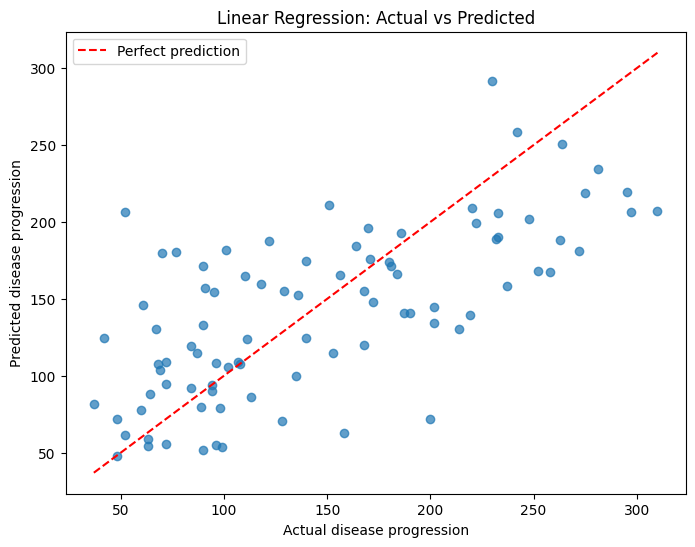

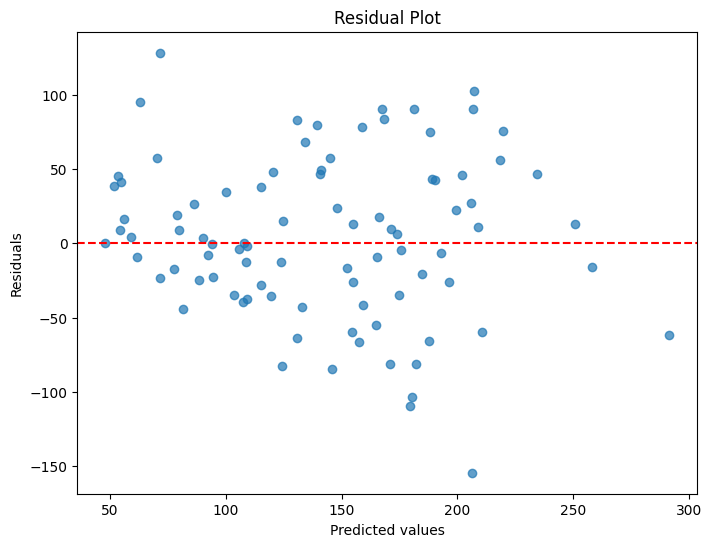

In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Perfect prediction')
plt.xlabel('Actual disease progression')
plt.ylabel('Predicted disease progression')
plt.title('Linear Regression: Actual vs Predicted')
plt.legend()
plt.show()

plt.figure(figsize=(8, 6))
residuals = y_test - y_pred
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel('Predicted values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

## Conclusion
Linear Regression gives a simple, interpretable baseline for predicting disease progression from the ten baseline measurements. The R-squared value shows how much of the variation in the target is explained by the features.